# Use Inscopix python API to align multiple calcium recordings from longitudinal sessions

Prerequisite: run through time series API template. The recording directory and cellset chosen for longitudinal registration should have been pre-processed and available for this template.

## Step 0. install jupyter notebook nbextensions to view table of contents


To best view and navigate this template, installing [jupyter notebook nbextensions](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/nbextensions/toc2/README.html) to show table of contents (TOC) sidebar is highly recommended.

1. After activating isxenv (conda activate isxenv), paste the following two lines into the command line one at a time (more instructions see [this link](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/install.html)).

```
pip install https://github.com/ipython-contrib/jupyter_contrib_nbextensions/tarball/master

jupyter contrib nbextension install --user
```

2. After the installation completes and "jupyter notebook" program is initiated (by typing "jupyter notebook" inside isxenv), a new nbextensions tab will appear to the right of the Files tab. Users can enable TOC within the nbextensions tab and toggle the TOC button on and off from the tool bar.


3. ExecuteTime is also recommended to be turned on in the nbextensions tab to view the execution time for each cell (or use %%time function instead in selective cells)

## Step 1. prepare files for analysis

### 1.1 import libraries

In [1]:
import isx  # Inscopix API
import os  # operating system
import json  # import json file
from pathlib import Path  # to work with dir
import textwrap  # to format multiline string message
from itertools import islice  # list manipulation
import numpy as np  # to manipulate data matrix
import numpy.matlib  # to manipulate data matrix
from scipy import stats  # calculate zscore
import pandas as pd  # data analysis library
import matplotlib.pyplot as plt  # data visualization
import matplotlib.lines as mlines  # figure legend styling
from functools import partial  # modify function default parameters
# to suppress warnings from the output window
import warnings
warnings.filterwarnings("ignore")

# to render the figures inside the current notebook
%matplotlib inline

### 1.2 load recordings dirs

### **USER INPUT REQUIRED (1 of 1)**

In [2]:
# make sure the folder structure is the same as in time series template

Parent_folder_User_defined = Path(r'D:\demo')

output_dir = \
    Parent_folder_User_defined /  \
    "S1prism_AAV1_demo_with_LR" /  \
    "S1prism_AAV1_demo_v2_data" /  \
    "processed"

# load the raw recording dirs from time series analysis
# they will be used as base names to add suffix and make new filenames.

with open(output_dir / 'series_rec_names.json') as file:
    series_rec_names = json.load(file)

In [3]:
# store the series label, list of recordings and
# the No. of recordings from each series

day_labels = list(series_rec_names.keys())
recordings_series = list(series_rec_names.values())
num_rec_per_series = [len(child_list) for child_list in recordings_series]

# print series label and the recording No. for each series
print('Label of time series:', day_labels)
print('Number of recordings for each day:', num_rec_per_series)

# print the recording list from one example series
print('{} recording list:'.format(day_labels[0]))

for each in recordings_series[0]:
    print(Path(each).name)

Label of time series: ['day_1', 'day_4']
Number of recordings for each day: [4, 4]
day_1 recording list:
recording_20160613_105808-PP-PP.isxd
recording_20160613_110507-PP-PP.isxd
recording_20160613_111207-PP-PP.isxd
recording_20160613_111907-PP-PP.isxd


### 1.3 define functions to add suffix or prefix to series filenames

In [4]:
def split2series(Input, length_to_split=num_rec_per_series):
    """
    Convert a straight list into a nested one, a list of time series.
    for example: [1, 2, 3, 4] --> [[1, 2], [3, 4]]
    given an input length [2, 2]

    Args:
        Input: straight list such as [1, 2, 3, 4]
        length_to_split: No. of elements to be distributed into nested lists
    Return:
        Output: Nested list such as [[1, 2], [3, 4]]
    """

    # Using islice to redistribute the elements from the input list
    Inputt = iter(Input)
    Output = [list(islice(Inputt, elem))
              for elem in length_to_split]
    return Output


def merge_series(Input):
    """
    Flatten a nested list, a list of time series into a single list
    for example: [[1, 2], [3, 4]] --> [1, 2, 3, 4]
    Args:
        Input: Nested list
    Return:
        Output: flattened list
    """
    if any(isinstance(i, list) for i in Input):
        Output = [recording for child_list in Input for recording in child_list]
    else:
        Output = Input
    return Output

def series_suffix(suffix, dir_series=recordings_series, output_dir=output_dir):

    """
    add suffix to series filename
    1. The input dir series are merged first
    2. The merged list is used to add suffix to filenames
    3. The new filenames list is split to new dir series
       if input list is nested

    Args:
        dir_series: input dir series
                    Default: raw recording dirs
        suffix: User input for filename suffixing
        output_dir: the output folder to store new files
                    Default: output dir specified from the previous step
    Return:
        Output: new dir series with suffixed filenames
    """

    old_names = merge_series(dir_series)  # step 1
    new_names = [str(Path(output_dir, Path(dir).stem \
        + suffix)) for dir in old_names]  # step 2
    if any(isinstance(i, list) for i in dir_series):
        num_rec = [len(child_list) for child_list in dir_series]
        Output = split2series(new_names, length_to_split=num_rec)
    else:
        Output = new_names  # step 3 skipped

    return Output

def series_label_prefix(suffix, prefix=day_labels, output_dir=output_dir):
    """
    join series label prefix with suffix input

Args:
        suffix: input, filename suffix to be joined
        prefix: series labels as prefix
        output_dir: the output folder to store dirs with new names
                    Default: output dir specified from the previous step
     Return:
        Output: new dir list with prefixed filenames
    """
    return [str(Path(output_dir, name + suffix)) for name in prefix]

### 1.4 load filenames from processed cellsets and df/f movie series from previous analysis.

In [5]:
"""
load the filenames of the input files for longitudinal registration.

abbreviation for filename suffix:

pp: preprocess
bp: bandpass filter
mc: motion correction
cnmfe-cellset: cnmfe cellset
dff: deltaF/F0
pca_ica: pca/ica cellset

"""

# load filenames from time series analysis
cnmfe_files_series = series_suffix('-PP-BP-MC-cnmfe-cellset.isxd')
dff_files_series = series_suffix('-PP-BP-MC-dff.isxd')

# cnmfe cellset will be used to demo the longitudinal registration procedure
# users are encouraged to try the same procedure on pca/ica cellsets.
pcaica_files_series = series_suffix('-PP-BP-MC-dff-pca_ica.isxd')

### 1.5 make new names for LR output files

In [6]:
"""

1. Recordings from both time series will be used for longitudinal registration
therefore we combine cnmfe cellset from all time series as one input list

cnmfe_cellset_lr_input1: merged cnmfe cellset before LR
cnmfe_cellset_lr_output1: merged cnmfe cellset after LR

2. The same transformation resulting from cnmfe cellset registration
can also be applied to a merged movie series.

For example dff movie will be used in this demo.

dff_files_lr_input2: merged dff movie series before LR
dff_files_lr_output2: merged dff movie series after LR

3. The cell index before and after LR will be stored in
a CSV file lr_csv_file and processed in Step 4 to categorize cell index
based on their active session(s).

"""

# make new filenames for longitudinal registration processing
cnmfe_cellset_lr_input1 = merge_series(cnmfe_files_series)
cnmfe_cellset_lr_output1 = series_suffix(
                        '-LR.isxd', dir_series=cnmfe_cellset_lr_input1)

dff_files_lr_input2 = merge_series(dff_files_series)
dff_files_lr_output2 = series_suffix(
                        '-LR.isxd', dir_series=dff_files_lr_input2)

lr_csv_file = str(output_dir / "lr_index_table.csv")

print("""
The cellset input for longitudinal registration now includes {} recordings
A movie list can be used as an optional second input
to apply the same transformation resulting from cnmfe cellset registration.
""".format(len(cnmfe_cellset_lr_input1)))


The cellset input for longitudinal registration now includes 8 recordings
A movie list can be used as an optional second input
to apply the same transformation resulting from cnmfe cellset registration.



## Step 2. apply longitudinal registration to align time series recordings from different days

### 2.1 apply longitudinal registration after merging cellset series

In [7]:
print('Applying longitudinal registration, please wait...\n')

if not os.path.exists(lr_csv_file):  # skip if output file already exists
    isx.longitudinal_registration(
        cnmfe_cellset_lr_input1,
        cnmfe_cellset_lr_output1,
        input_movie_files=dff_files_lr_input2,
        output_movie_files=dff_files_lr_output2,
        csv_file=lr_csv_file, accepted_cells_only=False)
    print('Longitudinal registration for {} and {} time series completed'
          .format(day_labels[0], day_labels[1]))
else:
    print(Path(lr_csv_file).name + " exists, process skipped\n")

Applying longitudinal registration, please wait...

Longitudinal registration for day_1 and day_4 time series completed


### 2.2 store the cellset dirs for a separate data visualization template

In [8]:
# store the output cnmfe cellset dirs

cnmfe_cellset_lr_series = {}
for day_i, key in enumerate(series_rec_names):
    cnmfe_cellset_lr_series[key] = split2series(
                                    cnmfe_cellset_lr_output1)[day_i]
with open(output_dir / "cnmfe_cellset_lr.json", 'w') as output_file:
    json.dump(cnmfe_cellset_lr_series, output_file)

dff_lr_series = {}
for day_i, key in enumerate(series_rec_names):
    dff_lr_series[key] = split2series(
                                    dff_files_lr_output2)[day_i]
with open(output_dir / "dff_files_lr.json", 'w') as output_file:
    json.dump(dff_lr_series, output_file)

## Step 3. apply maximal projection from post LR df/f movie series

### 3.1 apply maximal projection for  time series after LR

In [9]:
# make filenames for maximal projection image frame after LR
maxdff_files_lr = series_label_prefix('-maxdff-LR.isxd')

for day_i, day_label in enumerate(day_labels):
    if not os.path.exists(maxdff_files_lr[day_i]):  # skip if file exists
        isx.project_movie(
            input_movie_files=split2series(dff_files_lr_output2)[day_i],
            output_image_file=maxdff_files_lr[day_i],
            stat_type='max')  # types: 'mean', 'min', or 'max'
        print("maximal projection from {} dff time series completed".\
              format(day_label))
    else:
        print(Path(maxdff_files_lr[day_i]).stem + " exists, process skipped")

maximal projection from day_1 dff time series completed
maximal projection from day_4 dff time series completed


### 3.2 display the maximal projection image

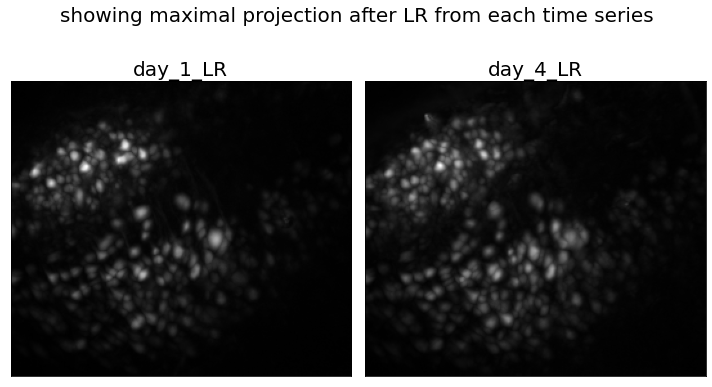

In [10]:
# set subplots, matching series No.
cols = min(2, len(day_labels))
rows = int(len(day_labels)/cols)
axes = []
fig = plt.figure(figsize=(10, 6))
fig.suptitle('showing maximal projection after LR from each time series', fontsize=20)

# display max projection of post-LR dff movie

for day_i, day_label in enumerate(day_labels):
    maxdff = isx.Image.read(maxdff_files_lr[day_i]).get_data()
    axes.append(fig.add_subplot(rows, cols, day_i+1))
    subplot_title = day_label+"_LR"
    axes[-1].set_title(subplot_title, fontsize=20)
    plt.imshow(maxdff, 'gray')
    plt.xticks([])
    plt.yticks([])

fig.tight_layout()
plt.show()

maxdff_files_series = {}
for day_i, key in enumerate(series_rec_names):
    maxdff_files_series[key] = maxdff_files_lr[day_i]
with open(output_dir / "maxdff_lr.json", 'w') as output_file:
    json.dump(maxdff_files_series, output_file)

## Step 4. process the index table and categorize cells based on their active session(s) index

### 4.1 load LR correspondence index table

In [11]:
# from the top rows:
# local cell index: cell index before LR
# global cell index: cell index after LR

lr_index_table = pd.read_csv(lr_csv_file)
lr_index_table.head(10)

,global_cell_index,local_cell_index,local_cellset_index,ncc_score,centroid_distance
0,0,0,0,1.000000,0.000000
1,0,0,1,1.000000,0.000000
2,0,0,2,1.000000,0.000000
3,0,0,3,1.000000,0.000000
4,0,0,4,0.992863,0.251899
5,0,0,5,0.992863,0.251899
6,0,0,6,0.992863,0.251899
7,0,0,7,0.992863,0.251899
8,1,1,0,1.000000,0.000000
9,1,1,1,1.000000,0.000000


### 4.2 replace local_cellset_index with local_series_index

In [12]:
"""

We will replace the local_cellset_index with local_series_index
since all recordings from the same series have redundant info such as local_cell_index.
We will then remove duplicated rows (keep one recording per series) in step 4.3.

"""
# set auto wrap off to fit all columns in the output window
pd.set_option('display.expand_frame_repr', False)

index_table = lr_index_table.iloc[:, 0:3]  # retrieve first 3 index cols
# calculate series index
series_index_filter = (index_table.local_cellset_index //
                       num_rec_per_series[0] == 0)
# add a new column local_series_index
index_table['local_series_index'] = np.where(series_index_filter, 0, 1)
# first column not shown due to save output space
print('after adding a new series index column\n', index_table)

# remove the local_cellset_index
del index_table['local_cellset_index']
print('\nafter removing the local_cellset_index col\n', index_table)

after adding a new series index column
       global_cell_index  local_cell_index  local_cellset_index  local_series_index
0                     0                 0                    0                   0
1                     0                 0                    1                   0
2                     0                 0                    2                   0
3                     0                 0                    3                   0
4                     0                 0                    4                   1
...                 ...               ...                  ...                 ...
2871                421               355                    7                   1
2872                422               357                    4                   1
2873                422               357                    5                   1
2874                422               357                    6                   1
2875                422               357      

### 4.3 remove duplicated rows

In [13]:
# cells with the duplicate global_cell_index are active in both sessions
# cells with unique global_cell_index are active only in a single session

index_table_clean = index_table.drop_duplicates().reset_index(drop=True)
print('after removing duplicated rows\n\n', index_table_clean)

after removing duplicated rows

      global_cell_index  local_cell_index  local_series_index
0                    0                 0                   0
1                    0                 0                   1
2                    1                 1                   0
3                    1                 7                   1
4                    2                 2                   0
..                 ...               ...                 ...
714                418               347                   1
715                419               348                   1
716                420               351                   1
717                421               355                   1
718                422               357                   1

[719 rows x 3 columns]


### 4.4 store global index values

In [14]:
# reorganize the clean table in a tabular format
# cells with only one local index value are uniquely active in one session
# cells with two local index values are coactive cells

idx_table=index_table_clean.pivot(
    index='global_cell_index', columns='local_series_index', \
    values ='local_cell_index').reset_index(drop=False)
print(idx_table.to_string(index=False))

 global_cell_index      0      1
                 0    0.0    0.0
                 1    1.0    7.0
                 2    2.0    NaN
                 3    3.0    1.0
                 4    4.0   19.0
                 5    5.0    4.0
                 6    6.0    6.0
                 7    7.0   10.0
                 8    8.0   21.0
                 9    9.0    8.0
                10   10.0   20.0
                11   11.0   13.0
                12   12.0    NaN
                13   13.0    NaN
                14   14.0    NaN
                15   15.0    NaN
                16   16.0    NaN
                17   17.0   14.0
                18   18.0    2.0
                19   19.0   22.0
                20   20.0    3.0
                21   21.0   15.0
                22   22.0   17.0
                23   23.0   26.0
                24   24.0    9.0
                25   25.0    5.0
                26   26.0   31.0
                27   27.0   28.0
                28   28.0    NaN
          

### 4.5 store the global index values for the three groups: active in each session and active in both

In [15]:
session_cell_index={}
session_cell_index[day_labels[0]] =list(
    idx_table[~idx_table[0].isnull() \
              & idx_table[1].isnull()].global_cell_index)
session_cell_index[day_labels[1]]=list(
    idx_table[idx_table[0].isnull() \
              & ~idx_table[1].isnull()].global_cell_index)
session_cell_index["{} and {}".format(day_labels[0], day_labels[1])] =list(
    idx_table[~idx_table[0].isnull() \
              & ~idx_table[1].isnull()].global_cell_index)

print("{} session only cell index values:\n".format(day_labels[0]),
    session_cell_index[day_labels[0]])

# store the index series for data visualization template
with open(output_dir / "session_cell_index.json", 'w') as output_file:
    json.dump(session_cell_index, output_file)

day_1 session only cell index values:
 [2, 12, 13, 14, 15, 16, 28, 52, 53, 55, 58, 60, 63, 64, 66, 68, 70, 72, 73, 74, 75, 76, 79, 80, 98, 110, 129, 130, 131, 132, 134, 135, 138, 140, 141, 142, 160, 165, 166, 167, 174, 187, 189, 197, 198, 199, 206, 208, 209, 210, 234, 264, 273, 278, 286, 287, 293, 295, 306, 308, 309, 318, 322, 324, 344, 345, 352, 363]
